# Parte Comum — Análise Exploratória (EDA) do dataset **Obesity**

**Projeto Final de AVD 2026.2** · Dataset: *Estimation of obesity levels based on eating habits and physical condition* (UCI 544).

2.111 pessoas do México, Peru e Colômbia, 16 atributos + 1 classe (`NObeyesdad`, 7 níveis de obesidade).
Segundo os autores, **77% das linhas foram geradas sinteticamente com SMOTE** e só 23% vieram diretamente do questionário web.
Esse detalhe vai aparecer várias vezes na análise.

A EDA segue os quatro pilares: **estrutural → distribucional → relacional → outliers**.
Todo o código das figuras está em `src/parte_comum/eda.py` (o mesmo script roda pela linha de comando).

In [1]:
import sys
from pathlib import Path

# Encontra a raiz do projeto (pasta que contém "src") para importar os módulos
RAIZ = Path.cwd().resolve()
while not (RAIZ / "src").exists() and RAIZ != RAIZ.parent:
    RAIZ = RAIZ.parent
sys.path.insert(0, str(RAIZ))

import numpy as np
import pandas as pd
from IPython.display import display

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 200)
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")
%matplotlib inline

from src import estilo
from src.parte_comum import dados as D
from src.parte_comum import eda as E

estilo.aplicar_estilo_mpl()
bruto = D.carregar_bruto("obesity")
df, log = D.limpar(bruto)

## 1. Pilar estrutural — dimensões, tipos e qualidade

In [2]:
print(f"Dimensões brutas: {bruto.shape[0]} linhas x {bruto.shape[1]} colunas")
print(f"Valores ausentes: {int(bruto.isna().sum().sum())}")
print(f"Linhas duplicadas: {int(bruto.duplicated().sum())}")
bruto.head()

Dimensões brutas: 2111 linhas x 17 colunas
Valores ausentes: 0
Linhas duplicadas: 24


,Gender,Age,Height,Weight,family_history_with_overweight,FAVC,FCVC,NCP,CAEC,SMOKE,CH2O,SCC,FAF,TUE,CALC,MTRANS,NObeyesdad
0,Female,21.000,1.620,64.000,yes,no,2.000,3.000,Sometimes,no,2.000,no,0.000,1.000,no,Public_Transportation,Normal_Weight
1,Female,21.000,1.520,56.000,yes,no,3.000,3.000,Sometimes,yes,3.000,yes,3.000,0.000,Sometimes,Public_Transportation,Normal_Weight
2,Male,23.000,1.800,77.000,yes,no,2.000,3.000,Sometimes,no,2.000,no,2.000,1.000,Frequently,Public_Transportation,Normal_Weight
3,Male,27.000,1.800,87.000,no,no,3.000,3.000,Sometimes,no,2.000,no,2.000,0.000,Frequently,Walking,Overweight_Level_I
4,Male,22.000,1.780,89.800,no,no,2.000,1.000,Sometimes,no,2.000,no,0.000,0.000,Sometimes,Public_Transportation,Overweight_Level_II


In [3]:
D.tabela_estrutural(bruto)

,coluna,descricao,tipo_estatistico,dtype_pandas,valores_unicos,faltantes,exemplos
0,Gender,Gênero,Qualitativa nominal (binária),str,2,0,"Female, Male"
1,Age,Idade (anos),Quantitativa contínua,float64,1402,0,"21.0, 23.0, 27.0"
2,Height,Altura (m),Quantitativa contínua,float64,1574,0,"1.62, 1.52, 1.8"
3,Weight,Peso (kg),Quantitativa contínua,float64,1525,0,"64.0, 56.0, 77.0"
4,family_history_with_overweight,Histórico familiar de sobrepeso,Qualitativa nominal (binária),str,2,0,"yes, no"
5,FAVC,Come alimentos calóricos com frequência,Qualitativa nominal (binária),str,2,0,"no, yes"
6,FCVC,"Frequência de consumo de vegetais (1=nunca, 2=...",Quantitativa ordinal (escala 1–3),float64,810,0,"2.0, 3.0, 1.0"
7,NCP,Número de refeições principais por dia (1 a 4),Quantitativa ordinal (escala 1–4),float64,635,0,"3.0, 1.0, 4.0"
8,CAEC,Come entre as refeições,Qualitativa ordinal (no < Sometimes < Frequent...,str,4,0,"Sometimes, Frequently, Always"
9,SMOKE,Fuma,Qualitativa nominal (binária),str,2,0,"no, yes"


**Leitura estrutural**

* 2.111 linhas × 17 colunas: **8 numéricas** (3 contínuas — idade, altura, peso — e 5 respostas de questionário em escala: FCVC, NCP, CH2O, FAF, TUE)
  e **9 qualitativas** (5 binárias, 2 ordinais de frequência — CAEC e CALC —, 1 nominal — MTRANS — e a classe, que é **ordinal**).
* **Nenhum valor ausente.** Há **24 linhas duplicadas**.
* **Inconsistência importante:** as 5 escalas de questionário deveriam ser inteiras (1, 2, 3…), mas aparecem com casas decimais.

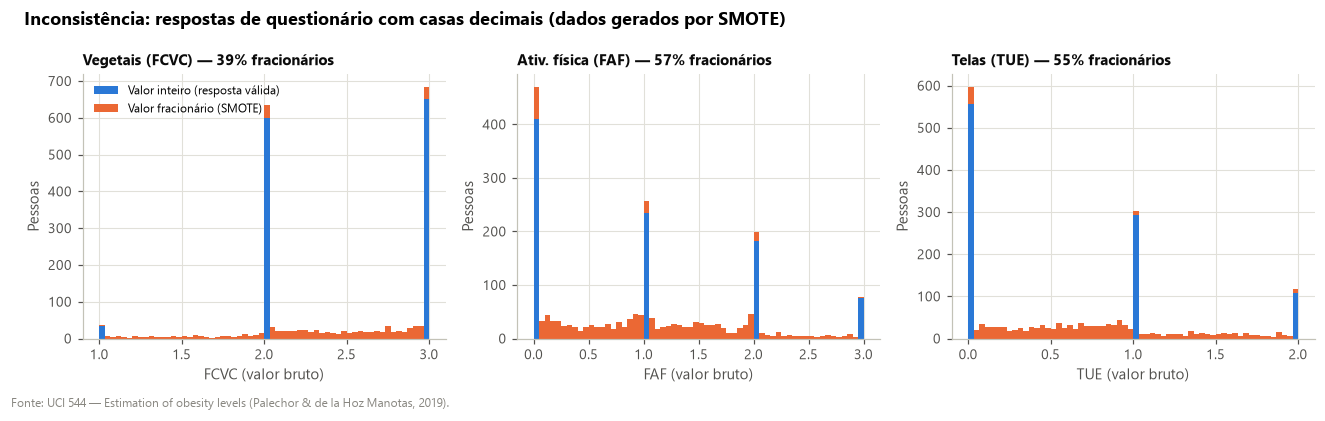

In [4]:
E.fig_sintetico(bruto);

Os valores fracionários (laranja) não existem no questionário: são o **rastro do SMOTE**, que cria pessoas novas interpolando
entre duas existentes (ex.: FCVC = 2,45). Isso confirma, pelos dados, o que a documentação diz sobre os 77% sintéticos.

### Tratamentos adotados

In [5]:
log

,etapa,linhas_afetadas,diagnostico,tratamento
0,Duplicatas,24,24 linhas idênticas a outra em todas as 17 col...,"Removidas (1,1% da base). Cópias dariam peso d..."
1,Inconsistência (dados sintéticos),1580,"FCVC, NCP, CH2O, FAF e TUE são respostas de qu...","Arredondadas para o inteiro mais próximo, rest..."
2,Faltantes,0,Nenhum valor ausente em nenhuma coluna.,Nenhum tratamento necessário.
3,Outliers,0,"Regra de Tukey: 167 idades acima de ~35 anos, ...",Mantidos: são pessoas reais/plausíveis e as cl...


In [6]:
print(f"Após a limpeza: {df.shape[0]} linhas. Novas colunas derivadas: IMC, classe (rótulo em português) e classe_codigo (0–6).")

Após a limpeza: 2087 linhas. Novas colunas derivadas: IMC, classe (rótulo em português) e classe_codigo (0–6).


## 2. Pilar distribucional

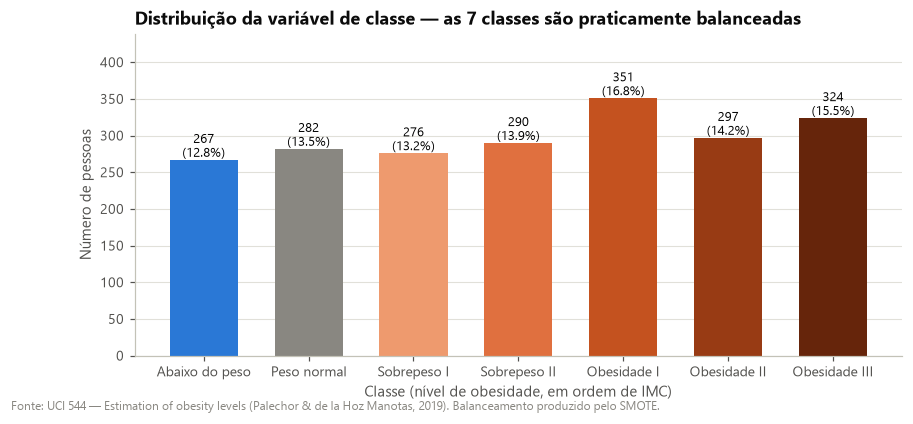

In [7]:
E.fig_classes(df);

As 7 classes estão **praticamente balanceadas** (267 a 351 pessoas, 12,8% a 16,8%). Na vida real a distribuição de obesidade nunca é assim:
o balanceamento é artificial, produzido pelo SMOTE. Consequência prática: "chutar a classe mais comum" acerta só **16,8%** — essa é a linha de base
para julgar o K-Means depois.

In [8]:
df[D.NUMERICAS + ["IMC"]].describe().T.assign(assimetria=df[D.NUMERICAS + ["IMC"]].skew())

,count,mean,std,min,25%,50%,75%,max,assimetria
Age,"2,087.000",24.353,6.369,14.000,19.916,22.848,26.000,61.000,1.514
Height,"2,087.000",1.703,0.093,1.450,1.630,1.702,1.769,1.980,-0.025
Weight,"2,087.000",86.859,26.191,39.000,66.000,83.101,108.016,173.000,0.242
FCVC,"2,087.000",2.426,0.585,1.000,2.000,2.000,3.000,3.000,-0.443
NCP,"2,087.000",2.703,0.797,1.000,3.000,3.000,3.000,4.000,-1.100
CH2O,"2,087.000",2.011,0.685,1.000,2.000,2.000,2.000,3.000,-0.015
FAF,"2,087.000",1.009,0.899,0.000,0.000,1.000,2.000,3.000,0.454
TUE,"2,087.000",0.670,0.674,0.000,0.000,1.000,1.000,2.000,0.509
IMC,"2,087.000",29.766,8.025,12.999,24.369,28.896,36.096,50.812,0.140


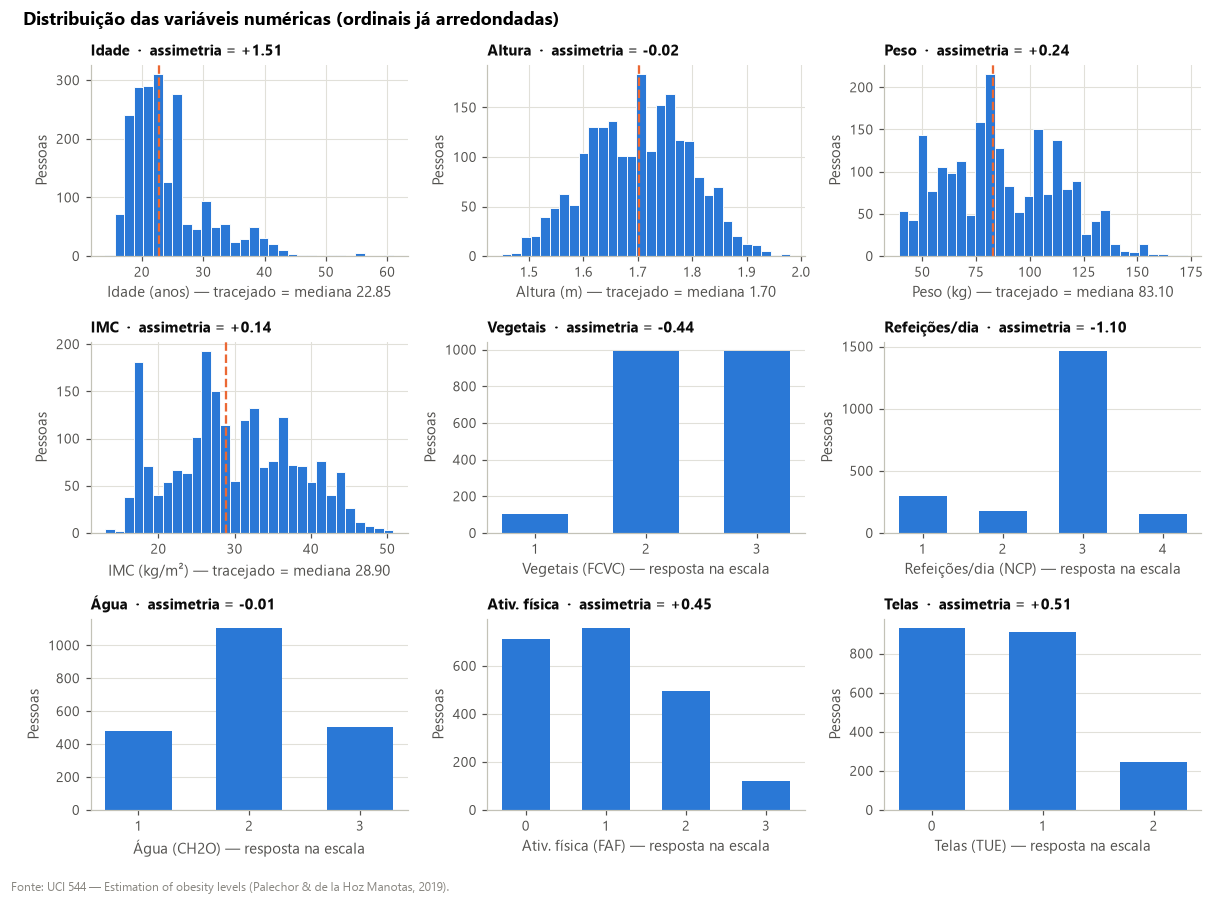

In [9]:
E.fig_numericas(df);

* **Idade** é fortemente assimétrica à direita (mediana ≈ 22,8 anos, assimetria ≈ +1,5): a amostra é de jovens/universitários; acima de ~35 anos há poucas pessoas.
* **Altura** é aproximadamente simétrica (1,45–1,98 m). **Peso** (39–173 kg) é espalhado e levemente bimodal — reflexo das classes balanceadas.
* **IMC** cobre de 13 a 51 kg/m² de forma quase uniforme, de novo pelo balanceamento artificial.
* Escalas: a maioria come **3 refeições** (NCP), bebe **1–2 L de água** (CH2O), faz **pouca atividade física** (FAF 0–1, 70%) e usa telas **até 5 h por dia** (TUE 0–1, 89%).

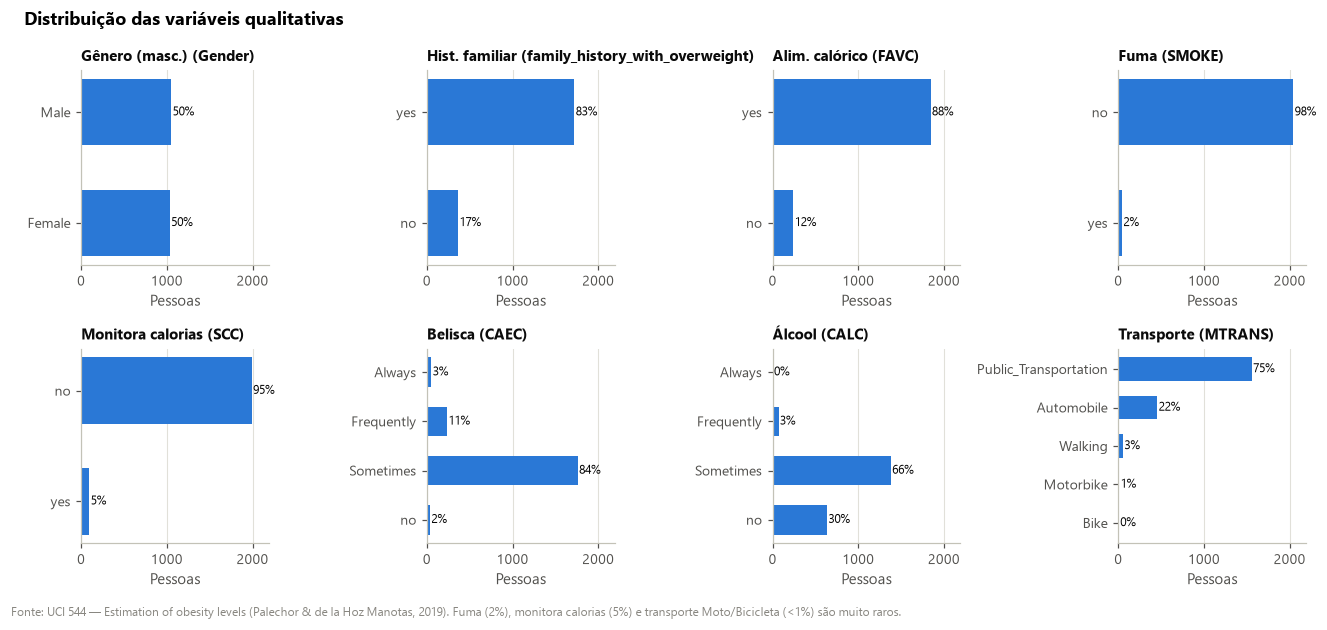

In [10]:
E.fig_categoricas(df);

* Gênero equilibrado (≈ 51% masculino). **82% têm histórico familiar de sobrepeso** e **88% comem alimentos calóricos com frequência** (FAVC).
* Fumar (2%), monitorar calorias (5%) e se deslocar de moto/bicicleta (< 1%) são **muito raros** — isso importa para o K-Means (ver notebook de agrupamento).
* CAEC ("belisca entre refeições") é dominado por *Sometimes* (84%); CALC (álcool) por *Sometimes* (66%) e *no* (30%); só **1 pessoa** respondeu *Always* em CALC.

## 3. Pilar relacional — relações entre todas as variáveis e com a classe

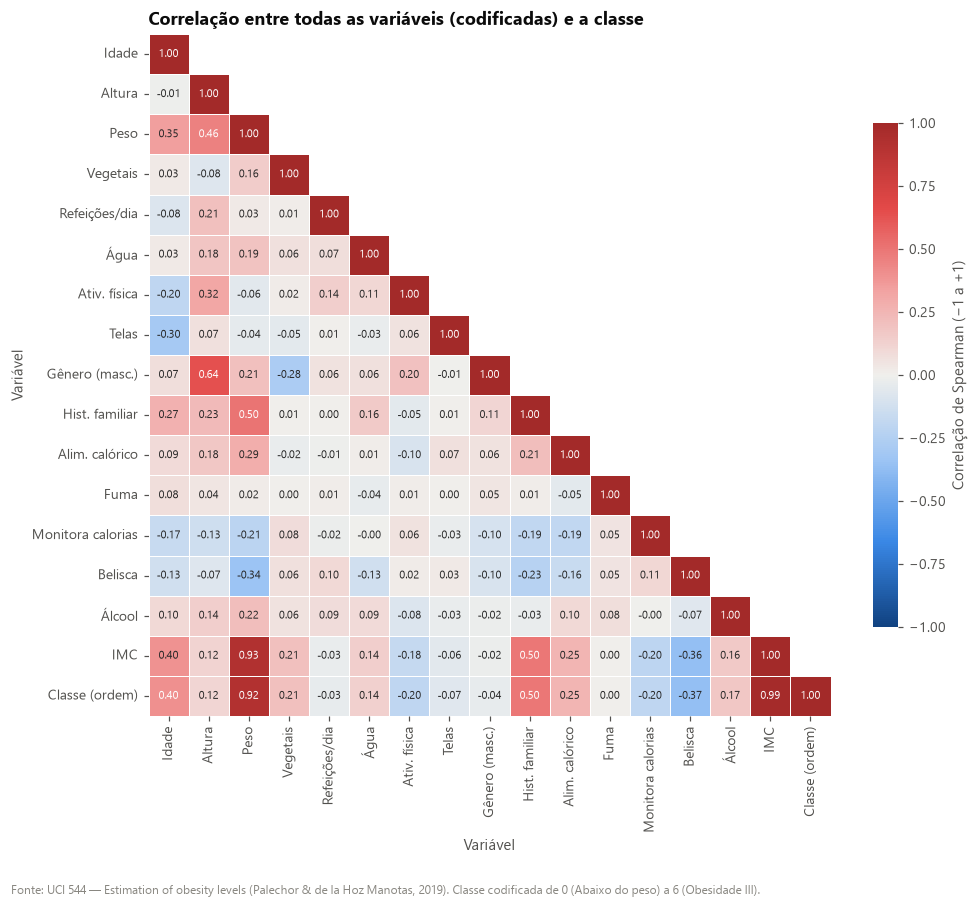

In [11]:
E.fig_correlacao(df);

Usamos **Spearman** (correlação por postos) porque metade das variáveis é ordinal e as relações não precisam ser lineares.

* **A classe é quase uma função do IMC (ρ = 0,99)** e, portanto, do **peso (ρ = 0,92)**. Isso não é coincidência: os níveis de obesidade são *definidos* por faixas de IMC.
* Entre os hábitos, as associações com a classe são moderadas ou fracas: histórico familiar (0,50), idade (0,40), beliscar entre refeições (−0,37, sinal contraintuitivo),
  alimentos calóricos (0,25), vegetais (0,21), atividade física (−0,20).
* Gênero e altura são fortemente associados (0,64), como esperado.

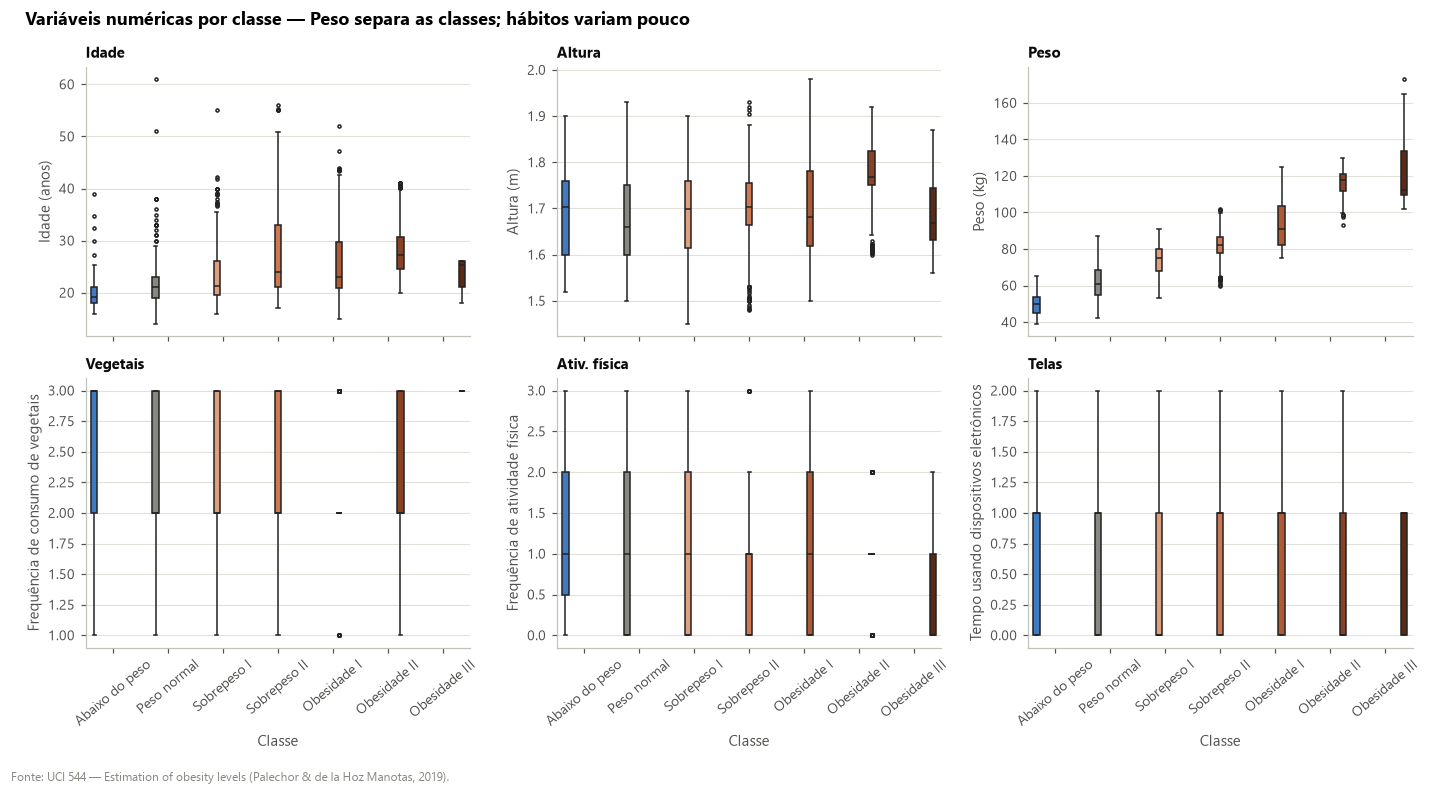

In [12]:
E.fig_numericas_por_classe(df);

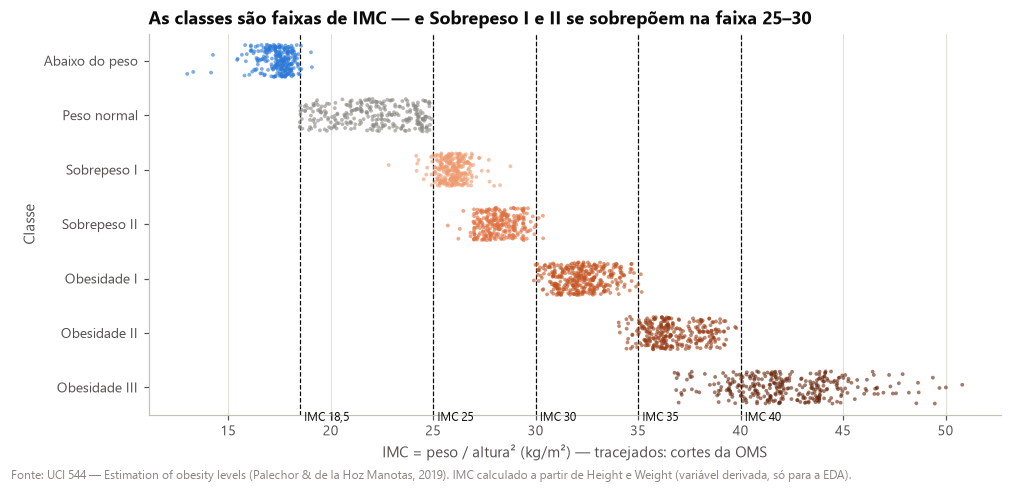

In [13]:
E.fig_imc_classe(df);

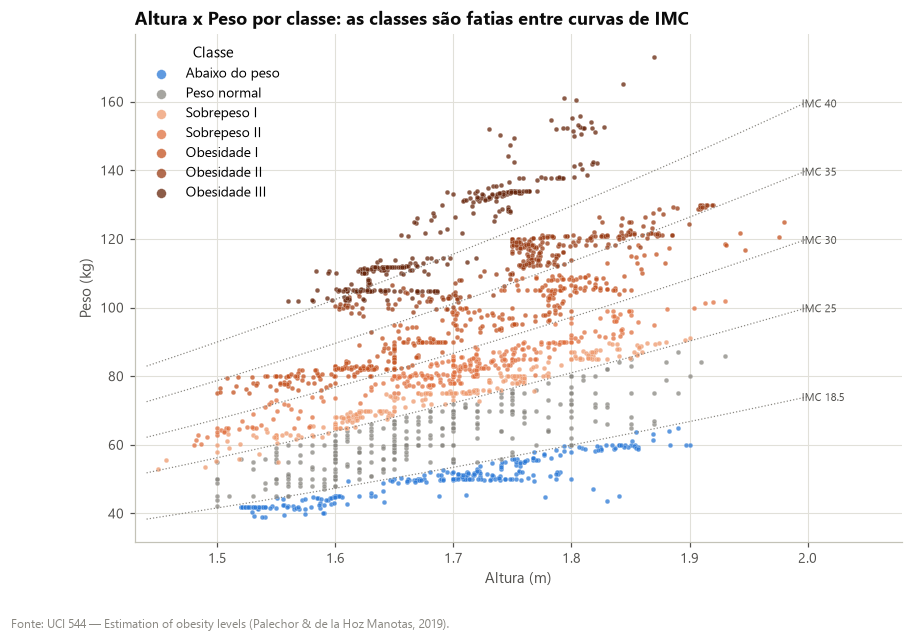

In [14]:
E.fig_altura_peso(df);

Os gráficos de IMC e de Altura × Peso mostram o ponto-chave da Parte Comum: **as classes são fatias de IMC**, separadas pelos cortes da OMS (18,5 / 25 / 30 / 35 / 40).

* **Sobrepeso I e Sobrepeso II se sobrepõem** (I: IMC 22,8–28,8; II: 25,7–30,4). A OMS não divide "sobrepeso" em dois níveis — essa subdivisão é do dataset e
  não corresponde a um corte claro nos dados.
* Obesidade II e III também se tocam (34–40 vs. 36,8–50,8).
* Como o IMC depende só de altura e peso, **uma análise que olhe para as 15 variáveis ao mesmo tempo (como o K-Means) vai "diluir" a informação que define a classe**.

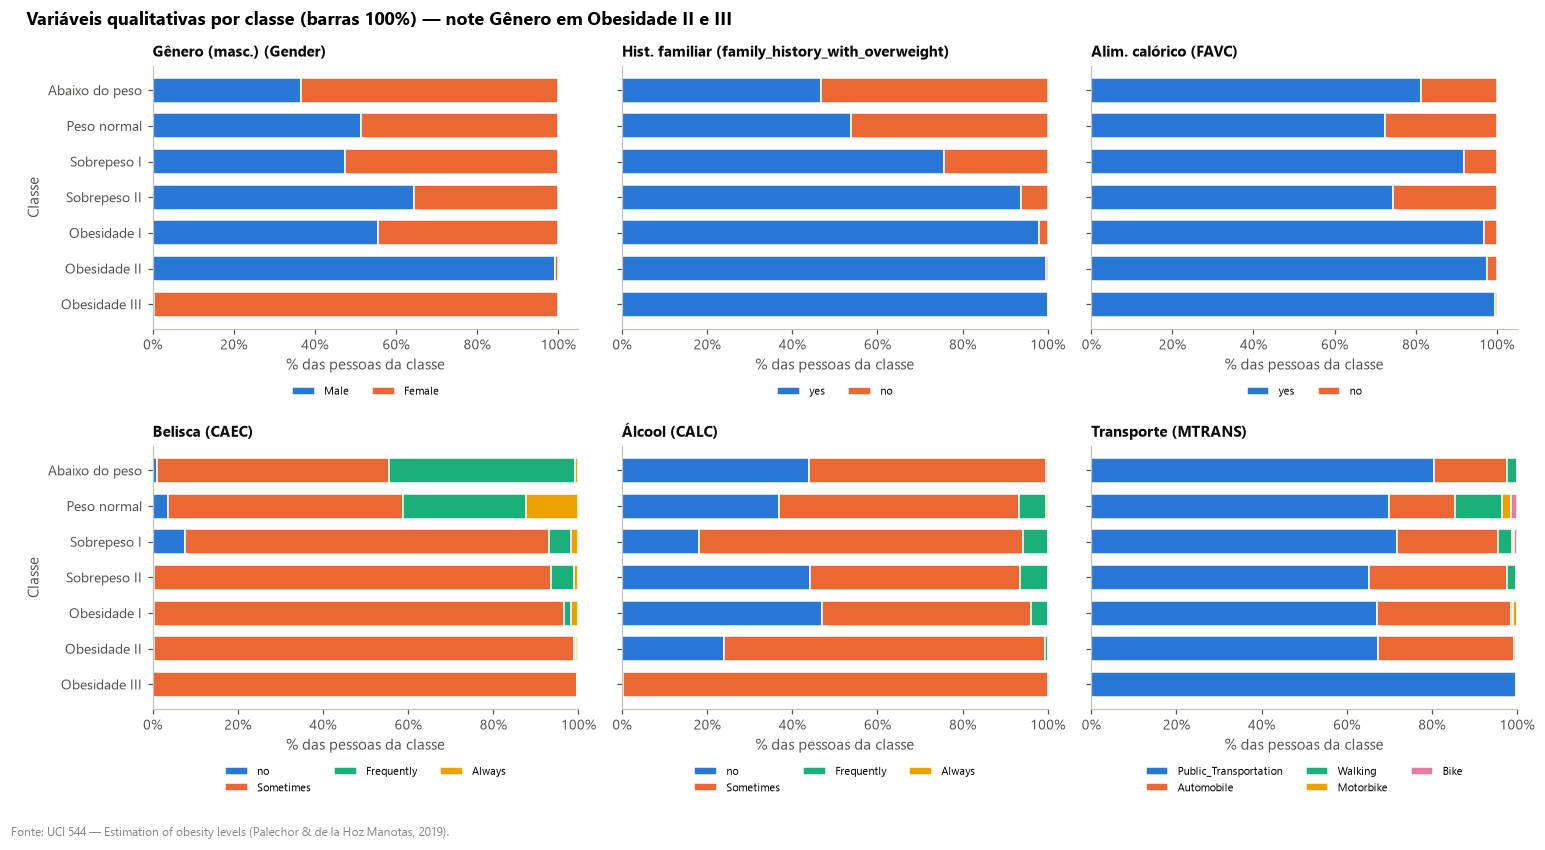

In [15]:
E.fig_categoricas_por_classe(df);

In [16]:
pd.crosstab(df["classe"], df["Gender"], margins=True)

Gender,Female,Male,All
classe,,,
Abaixo do peso,169,98,267
Peso normal,137,145,282
Sobrepeso I,145,131,276
Sobrepeso II,103,187,290
Obesidade I,156,195,351
Obesidade II,2,295,297
Obesidade III,323,1,324
All,1035,1052,2087


**Artefato do SMOTE:** Obesidade II tem **295 homens e 2 mulheres**; Obesidade III tem **323 mulheres e 1 homem**. Não existe razão biológica para isso — o SMOTE
gerou as pessoas sintéticas dessas classes a partir de pouquíssimos casos reais, copiando o gênero (e outros hábitos) desses poucos "pais".
Obesidade III também tem **323 de 324** pessoas com *Sometimes* em álcool, *Sometimes* em beliscar e transporte público. Resultado: essas classes ficam artificialmente homogêneas,
o que vai facilitar para o K-Means "achar" Obesidade III.

## 4. Pilar de outliers

In [17]:
E.tabela_outliers(df)

,variavel,q1,q3,iqr,limite_inf,limite_sup,n_outliers_iqr,n_outliers_z3,min,max
0,Age,19.916,26.000,6.084,10.790,35.126,167,23,14.000,61.000
1,Height,1.630,1.769,0.139,1.421,1.978,1,0,1.450,1.980
2,Weight,66.000,108.016,42.016,2.976,171.040,1,1,39.000,173.000
3,FCVC,2.000,3.000,1.000,0.500,4.500,0,0,1.000,3.000
4,NCP,3.000,3.000,0.000,3.000,3.000,621,0,1.000,4.000
5,CH2O,2.000,2.000,0.000,2.000,2.000,980,0,1.000,3.000
6,FAF,0.000,2.000,2.000,-3.000,5.000,0,0,0.000,3.000
7,TUE,0.000,1.000,1.000,-1.500,2.500,0,0,0.000,2.000
8,IMC,24.369,36.096,11.727,6.779,53.685,0,0,12.999,50.812


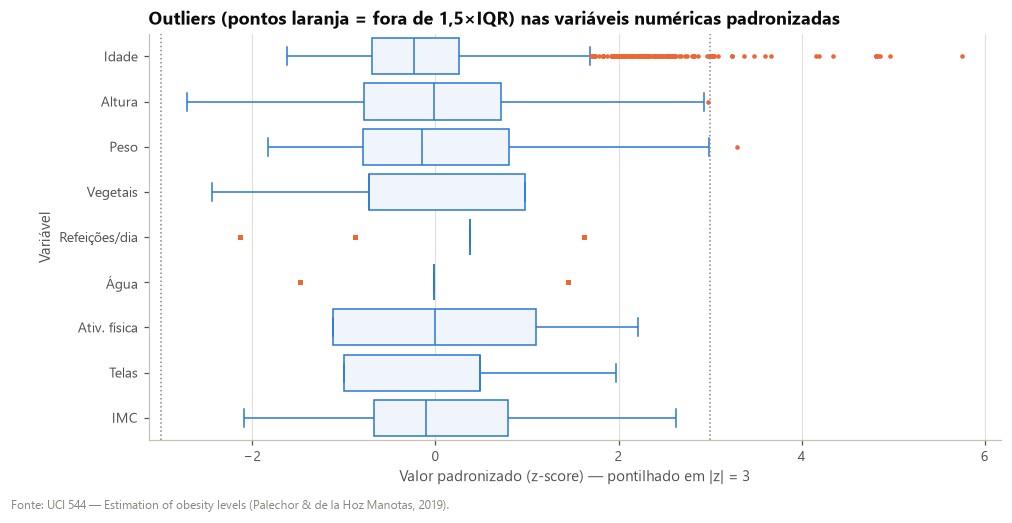

In [18]:
E.fig_outliers(df);

**Diagnóstico e decisão**

* **Idade:** 167 pessoas acima do limite de Tukey (~35 anos). São adultos mais velhos, perfeitamente plausíveis (máximo 61 anos). **Mantidos.**
* **Altura e peso:** 1 caso cada (1,98 m e 173 kg) — plausíveis e essenciais para as classes extremas (Obesidade III). **Mantidos.**
* **NCP e CH2O** "acusam" centenas de outliers, mas só porque o IQR deles é **zero** (quase todos respondem 3 refeições / 2 L). A regra de Tukey não serve para
  escalas discretas de 3–4 pontos; esses valores são respostas válidas. **Mantidos.**
* Nenhum valor com |z| > 3 é erro de medida. Remover outliers aqui tiraria justamente as pessoas que definem as classes extremas.
  A **padronização (z-score)** antes do K-Means já controla o efeito de escala dessas variáveis.

## 5. Síntese da EDA

1. Base limpa: **2.087 pessoas** (24 duplicatas removidas), escalas de questionário arredondadas, sem faltantes.
2. A classe é praticamente **o IMC discretizado** (ρ = 0,99). Hábitos alimentares e físicos têm associação apenas fraca a moderada com ela.
3. O balanceamento e a homogeneidade de algumas classes (Obesidade II só de homens, Obesidade III só de mulheres) são **artefatos do SMOTE**.
4. Expectativa para o K-Means: grupos que reflitam **gênero e peso** mais do que as 7 classes, e confusão entre classes vizinhas (Sobrepeso I/II, Normal/Sobrepeso I).